# Exploratory Data Analysis — Composite Cement Strength

This notebook explores the raw dataset (`data/raw/Concrete_Data.csv`) before
modelling. It checks data quality, looks at the target and feature
distributions, and measures how each mixture component relates to compressive
strength.

**Sections**

1. Setup and data loading
2. Data quality checks
3. Target distribution
4. Feature distributions
5. Correlations
6. Relationships with strength
7. Water–binder ratio
8. Outliers
9. Key takeaways

## 1. Setup and data loading

Paths and the target column come from `config.yaml`, so the notebook always
uses the same configuration as the pipeline.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Works when the notebook is opened from the project root or from notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

with open(PROJECT_ROOT / "config.yaml", encoding="utf-8") as file:
    config = yaml.safe_load(file)

TARGET = config["data"]["target"]
df = pd.read_csv(PROJECT_ROOT / config["data"]["path"])

print(f"Loaded {len(df):,} rows and {df.shape[1]} columns")
print(f"Target column: {TARGET!r}")

Loaded 1,030 rows and 9 columns
Target column: 'Concrete compressive strength(MPa, megapascals) '


The raw column names are long because they include component numbers
and units. A small helper creates short labels for plots; the pipeline itself
keeps the original names.

In [2]:
def short_name(column):
    """Turn a long dataset column name into a short label."""
    if column == TARGET:
        return "strength"
    return column.split("(")[0].strip().lower().replace(" ", "_")


edf = df.rename(columns={column: short_name(column) for column in df.columns})
edf.columns.tolist()

['cement',
 'blast_furnace_slag',
 'fly_ash',
 'water',
 'superplasticizer',
 'coarse_aggregate',
 'fine_aggregate',
 'age',
 'strength']

## 2. Data quality checks

In [3]:
quality = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "missing": df.isna().sum(),
        "unique": df.nunique(),
    }
)
quality

,dtype,non_null,missing,unique
Cement (component 1)(kg in a m^3 mixture),float64,1030,0,278
Blast Furnace Slag (component 2)(kg in a m^3 mixture),float64,1030,0,185
Fly Ash (component 3)(kg in a m^3 mixture),float64,1030,0,156
Water (component 4)(kg in a m^3 mixture),float64,1030,0,195
Superplasticizer (component 5)(kg in a m^3 mixture),float64,1030,0,111
Coarse Aggregate (component 6)(kg in a m^3 mixture),float64,1030,0,284
Fine Aggregate (component 7)(kg in a m^3 mixture),float64,1030,0,302
Age (day),int64,1030,0,14
"Concrete compressive strength(MPa, megapascals)",float64,1030,0,845


In [4]:
print(f"Rows:            {len(df):,}")
print(f"Columns:         {df.shape[1]}")
print(f"Duplicate rows:  {df.duplicated().sum():,}")
print(f"Missing values:  {int(df.isna().sum().sum())}")

Rows:            1,030
Columns:         9
Duplicate rows:  25
Missing values:  0


The dataset has no missing values. The pipeline still supports median
or mean imputation, and drops duplicate rows during preprocessing, because
those settings matter when you plug in a different CSV.

## 3. Target distribution

In [5]:
edf["strength"].describe().round(2)

count    1030.00
mean       35.82
std        16.71
min         2.33
25%        23.71
50%        34.44
75%        46.14
max        82.60
Name: strength, dtype: float64

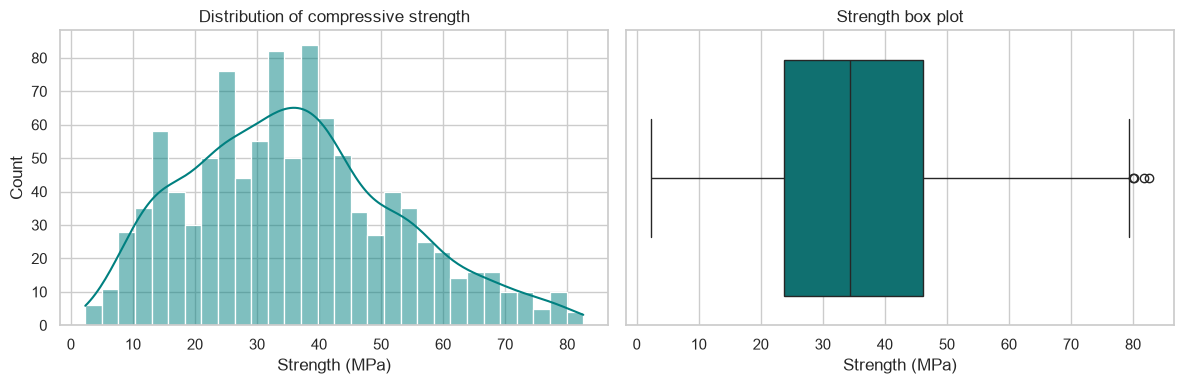

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(edf["strength"], bins=30, kde=True, color="teal", ax=axes[0])
axes[0].set_title("Distribution of compressive strength")
axes[0].set_xlabel("Strength (MPa)")
axes[0].set_ylabel("Count")

sns.boxplot(x=edf["strength"], color="teal", ax=axes[1])
axes[1].set_title("Strength box plot")
axes[1].set_xlabel("Strength (MPa)")

plt.tight_layout()

Strength is a continuous variable ranging from **2.33 to 82.60 MPa**
(mean 35.82, median 34.44). The distribution is right-skewed: most mixtures
fall in the low-to-middle range, with a tail of very strong mixes. The high
values in the box plot are plausible concrete strengths, not data errors.

## 4. Feature distributions

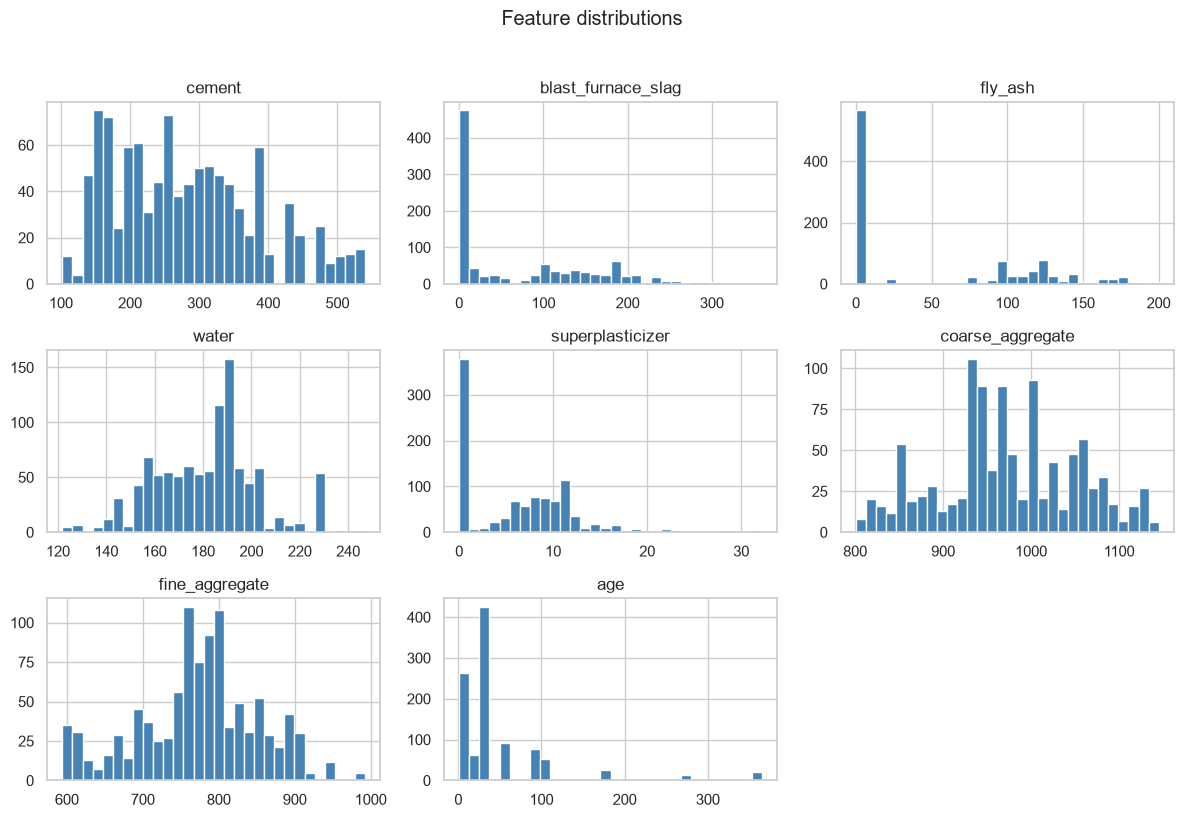

In [7]:
feature_columns = [column for column in edf.columns if column != "strength"]

edf[feature_columns].hist(
    figsize=(12, 8), bins=30, color="steelblue", edgecolor="white"
)
plt.suptitle("Feature distributions", y=1.02)
plt.tight_layout()

The features use very different scales (kg per m³ for the components,
days for age). The models in this project are tree-based, so no scaling is
required; this would matter for linear models.

Cement, the aggregates and water dominate the composition. Slag, fly ash and
superplasticizer are zero for many mixtures, which produces the spikes at zero
in their histograms.

## 5. Correlations

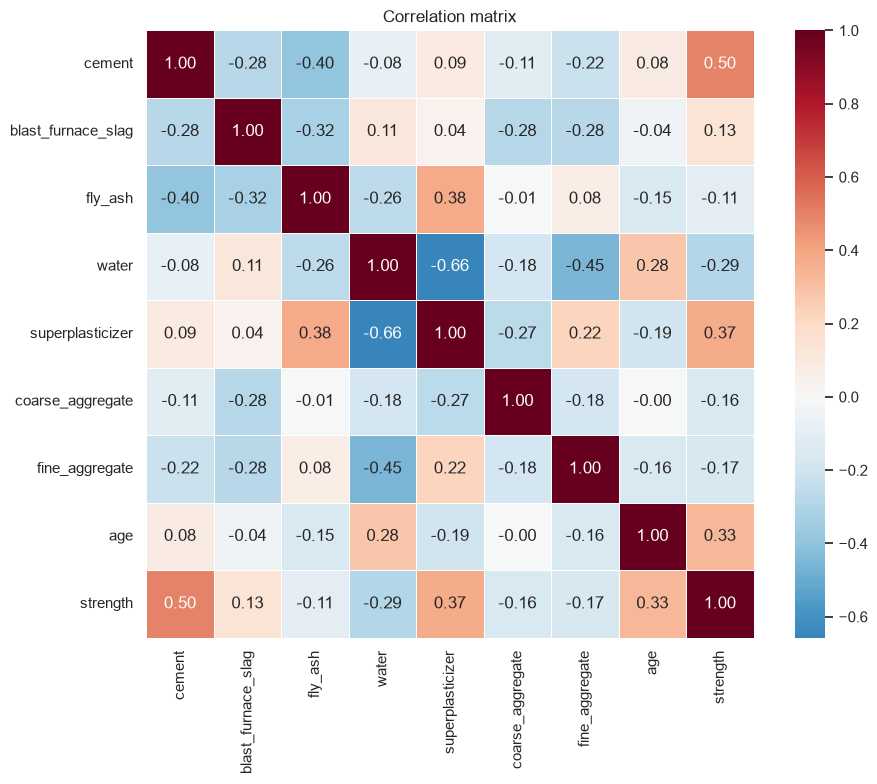

In [8]:
correlations = edf.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
)
ax.set_title("Correlation matrix")
plt.tight_layout()

cement                0.498
superplasticizer      0.366
age                   0.329
water                -0.290
fine_aggregate       -0.167
coarse_aggregate     -0.165
blast_furnace_slag    0.135
fly_ash              -0.106
Name: strength, dtype: float64

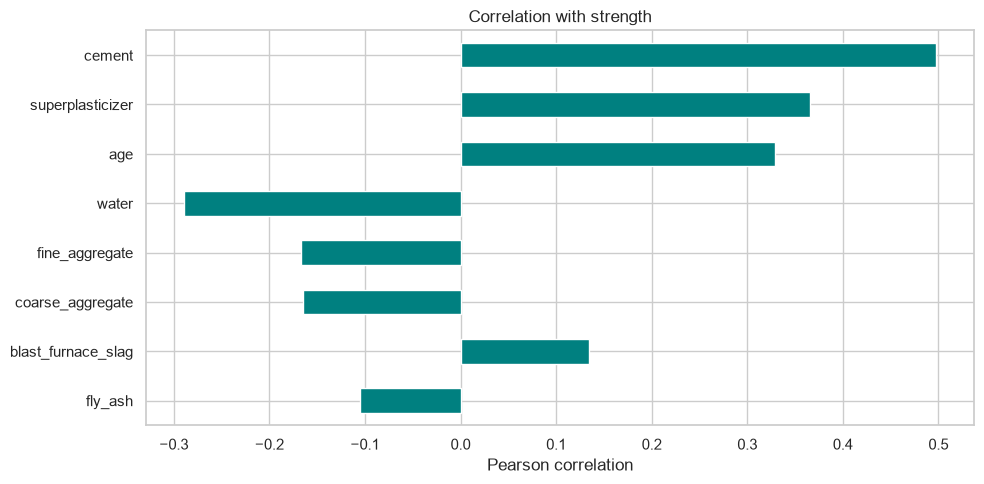

In [9]:
target_correlations = (
    correlations["strength"].drop("strength").sort_values(key=abs, ascending=False)
)

fig, ax = plt.subplots()
target_correlations.plot(kind="barh", color="teal", ax=ax)
ax.invert_yaxis()
ax.set_title("Correlation with strength")
ax.set_xlabel("Pearson correlation")
ax.set_ylabel("")
plt.tight_layout()

target_correlations.round(3)

Cement has the strongest positive correlation with strength (0.50),
followed by superplasticizer (0.37) and age (0.33). Water has the clearest
negative correlation (-0.29). The aggregate columns are correlated with each
other, which is expected because mixtures are constrained by volume: more of
one component usually means less of another.

## 6. Relationships with strength

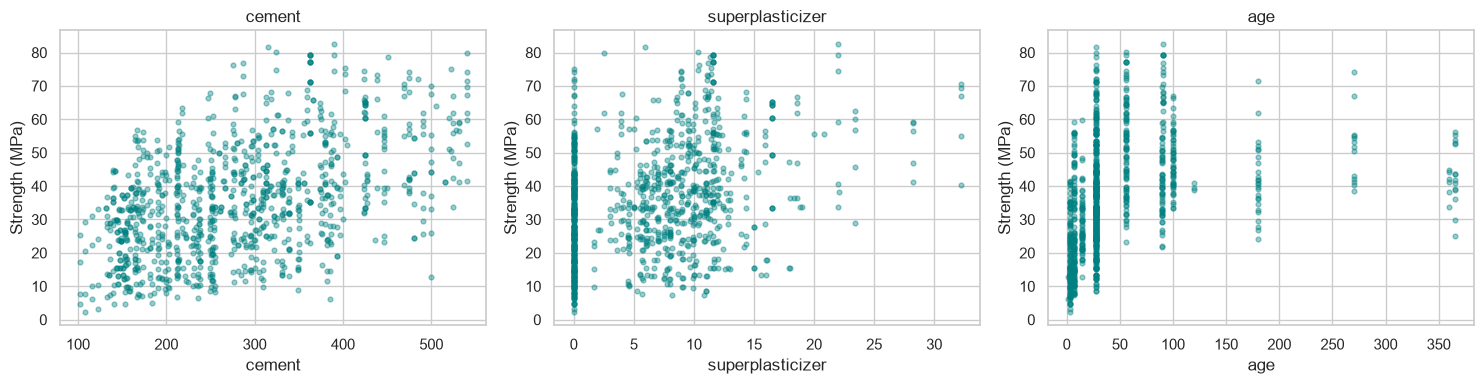

In [10]:
top_features = target_correlations.index[:3]

fig, axes = plt.subplots(1, len(top_features), figsize=(15, 4))
for ax, feature in zip(axes, top_features):
    ax.scatter(edf[feature], edf["strength"], s=12, alpha=0.4, color="teal")
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Strength (MPa)")

plt.tight_layout()

,mean,count
age,,
1,9.46,2
3,18.98,134
7,26.05,126
14,28.75,62
28,36.75,425
56,51.89,91
90,40.48,54
91,69.81,22
100,47.67,52


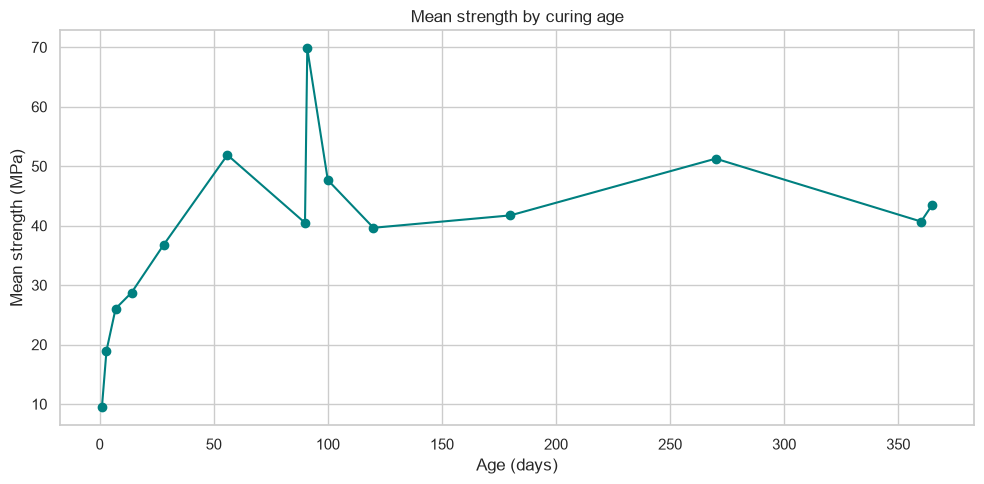

In [11]:
strength_by_age = edf.groupby("age")["strength"].agg(["mean", "count"])

fig, ax = plt.subplots()
ax.plot(strength_by_age.index, strength_by_age["mean"], marker="o", color="teal")
ax.set_title("Mean strength by curing age")
ax.set_xlabel("Age (days)")
ax.set_ylabel("Mean strength (MPa)")
plt.tight_layout()

strength_by_age.head(10).round(2)

The scatter plots show that strength rises with cement content,
superplasticizer and curing age. The age curve rises overall, though the
oldest groups contain few samples and are noisier. Most of the strength gain
happens in the first month. Tree models capture these non-linear trends
automatically, which is one reason they suit this dataset.

## 7. Water–binder ratio

A common domain feature is the water–binder ratio:
`water / (cement + slag + fly ash)`. Lower ratios usually mean denser concrete
and higher strength.

Correlation with strength: -0.623


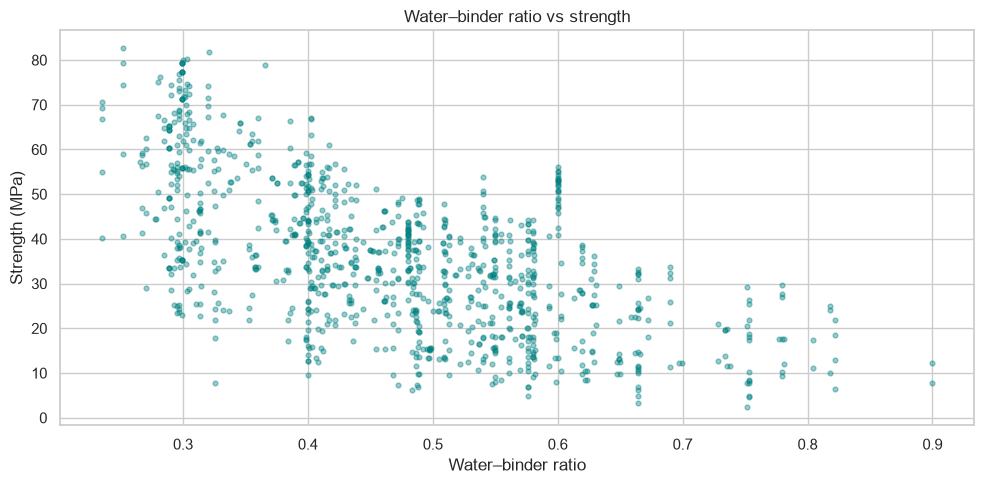

In [12]:
binder = edf["cement"] + edf["blast_furnace_slag"] + edf["fly_ash"]
edf["water_binder_ratio"] = edf["water"] / binder.replace(0, np.nan)

ratio_correlation = edf[["water_binder_ratio", "strength"]].corr().iloc[0, 1]
print(f"Correlation with strength: {ratio_correlation:.3f}")

fig, ax = plt.subplots()
ax.scatter(
    edf["water_binder_ratio"], edf["strength"], s=12, alpha=0.4, color="teal"
)
ax.set_title("Water–binder ratio vs strength")
ax.set_xlabel("Water–binder ratio")
ax.set_ylabel("Strength (MPa)")
plt.tight_layout()

The water–binder ratio correlates with strength at **-0.62**, a much
stronger signal than raw water content. It is a good candidate for a derived
feature if you move beyond the raw columns.

## 8. Outliers

In [13]:
q1 = edf[feature_columns].quantile(0.25)
q3 = edf[feature_columns].quantile(0.75)
iqr = q3 - q1

outliers = (
    (edf[feature_columns] < (q1 - 1.5 * iqr))
    | (edf[feature_columns] > (q3 + 1.5 * iqr))
).sum()

outliers.sort_values(ascending=False).to_frame("outlier_rows")

,outlier_rows
age,59
superplasticizer,10
water,9
fine_aggregate,5
blast_furnace_slag,2
cement,0
fly_ash,0
coarse_aggregate,0


Several features have IQR outliers, but they represent unusual yet
valid concrete mixes rather than measurement errors. Most flagged values are
in `age`, which has a long tail of older test ages. Tree-based models are not
sensitive to their scale, so the pipeline keeps them.

## 9. Key takeaways

- The dataset has **1,030 rows × 9 columns** (8 features + 1 target), **no
  missing values** and **25 duplicate rows**, which preprocessing removes.
- The target, compressive strength, ranges from **2.33 to 82.60 MPa** and is
  right-skewed (mean 35.82, median 34.44).
- **Cement** (0.50), **superplasticizer** (0.37) and **age** (0.33) are the
  strongest positive correlates of strength; **water** (-0.29) is negative.
- The relationship with age is non-linear, which favours tree-based models
  over plain linear regression.
- The **water–binder ratio** correlates with strength at **-0.62** and is a
  useful derived feature.
- Feature scales differ, but the tree-based models in this project do not
  need scaling.

**Next step:** run the pipeline with `python main.py run-all` and inspect
`artifacts/reports/evaluation.json` for the model scores.